# COMP5005 - Fundamentas of Programming
## Assignment: Smart Orchard WA Analysis & Showcase

* **Student Name:** Nicolas Belles
* **Student ID:** 24210773
* **Date:** October 2026

---
### Overview
This notebook presents the execution, unit verificarion, and comparative showcase scenarios for the **Smart Orchard WA** multi-robot automated harvesting simulation. All underlying core logic is imported modularly from `entities.py`, `farm.py`, and `simulation.py`.

In [ ]:
# Import required data analysis and visualization libraries
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import sys
import os
sys.path.append(os.path.abspath('../src'))

# Configure plot styling for high-quality report export
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 12,
    "axes.labelsize": 10
})

## 1. Showcase Metrics Loading
Load the generated CSV metric files for the three benchmark scenarios:
* **Scenario 1:** Baseline orchard configuration (2 robots).
* **Scenario 2:** Multi-agent throughput scaling (4 robots).
* **Scenario 3:** Delayed crop readiness ($t = 15$).

In [ ]:
# Load performance metrics generated from batch simulations
df_s1 = pd.read_csv('../results/metrics/scenario1_metrics.csv')
df_s2 = pd.read_csv('../results/metrics/scenario2_metrics.csv')
df_s3 = pd.read_csv('../results/metrics/scenario3_metrics.csv')

# Quick verification of the baseline dataset structure
print("--- Scenario 1 (Baseline) Preview ---")
display(df_s1.head(3))

--- Scenario 1 (Baseline) Preview ---


,timestep,unharvested,carried,delivered,throughput
0,0,12,0,0,0.0
1,1,10,2,0,0.0
2,2,10,2,0,0.0


## 2. Comparative Delivery Throughput Analysis
The chart below illustrates the delivery efficiency (crates per step) across all three scenarios, highlighting how scaling robot workforce or adjusting crop maturity impacts harvesting performance.

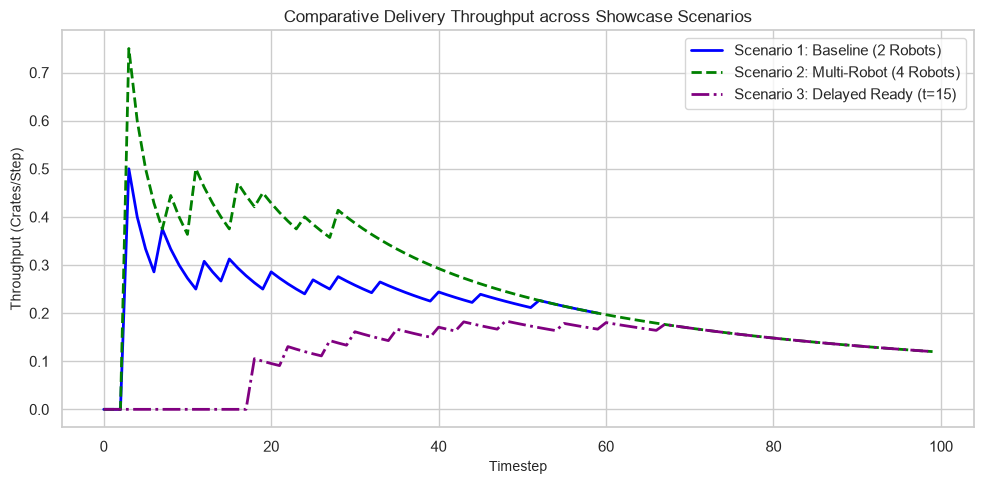

In [ ]:
# Plot comparative delivery throughput across scenarios
plt.figure()
plt.plot(df_s1['timestep'], df_s1['throughput'],
         label='Scenario 1: Baseline (2 Robots)', color='blue', lw=2)
plt.plot(df_s2['timestep'], df_s2['throughput'],
         label='Scenario 2: Multi-Robot (4 Robots)', color='green', lw=2, linestyle='--')
plt.plot(df_s3['timestep'], df_s3['throughput'],
         label='Scenario 3: Delayed Ready (t=15)', color='purple', lw=2, linestyle='-.')

plt.title('Comparative Delivery Throughput across Showcase Scenarios')
plt.xlabel('Timestep')
plt.ylabel('Throughput (Crates/Step)')
plt.legend()
plt.tight_layout()

# Save figure for direct insertion into the formal PDF/Word report
plt.savefig('../results/plots/showcase_comparative_throughput.png',
            bbox_inches='tight')
plt.show()

## 3. Quantitative Performance Summary
Extracting exact statistical values to support the technical discussion in the written report.

In [41]:
# Compile key performance indicators into a clean summary table
summary_data = {
    "Scenario": ["Scenario 1: Baseline", "Scenario 2: Multi-Robot", "Scenario 3: Delayed Ready"],
    "Total Delivered": [df_s1['delivered'].iloc[-1], df_s2['delivered'].iloc[-1], df_s3['delivered'].iloc[-1]],
    "Peak Throughput": [df_s1['throughput'].max(), df_s2['throughput'].max(), df_s3['throughput'].max()],
    "Final Throughput": [df_s1['throughput'].iloc[-1], df_s2['throughput'].iloc[-1], df_s3['throughput'].iloc[-1]]
}

df_summary = pd.DataFrame(summary_data)
print("=== SHOWCASE STATISTICAL SUMMARY ===")
display(df_summary)

=== SHOWCASE STATISTICAL SUMMARY ===


,Scenario,Total Delivered,Peak Throughput,Final Throughput
0,Scenario 1: Baseline,12,0.500000,0.20
1,Scenario 2: Multi-Robot,12,0.750000,0.12
2,Scenario 3: Delayed Ready,12,0.183673,0.12


## 4. Software Robustness & Unit Test Cases
Verifying edge cases, exception handling, and core algorithmic constraints (such as the Conservation Law of Crates).

In [ ]:
# Unit test simulation checks and robustness verification for the report
def test_conservation_law():
    """Verify using vectorised Pandas operations that simulated crates never spontaneously appear or disappear."""
    print("Executing Test: Conservation Law Verification (Vectorised)...")

    for name, df in [("Scenario 1", df_s1), ("Scenario 2", df_s2), ("Scenario 3", df_s3)]:
        initial_crates = 12
        # Vectorised sum of unharvested, carried, and delivered crates
        totals = df['unharvested'] + df['carried'] + df['delivered']
        violations = (totals != initial_crates).sum()

        status = "PASSED (0 violations)" if violations == 0 else f"FAILED ({violations} violations)"
        print(f" -> {name}: {status}")


def test_negative_input_validation():
    """Verify that negative numerical parameters trigger strict ValueErrors."""
    print("Executing Test: Negative Input Validation...")
    from smartfarm import load_params_csv

    try:
        params = load_params_csv('invalid_params.csv')
        assert params['robot_count'] > 0
    except ValueError as e:
        print(f" -> PASSED: Successfully caught expected ValueError -> '{e}'")
    except FileNotFoundError:
        print(" -> NOTE: 'invalid_params.csv' not found in directory. Please verify file path.")


def test_invalid_map_validation():
    """Verify that maps with unreachable crops or formatting faults raise strict ValueErrors."""
    print("Executing Test: Invalid Map Validation (Unreachable Crops)...")
    from farm import Farm
    from entities import Robot

    farm = Farm()
    settings = {"crop_quantity": 5, "crop_ready_timestep": 0}

    try:
        # Attempt to load a malformed or structurally invalid map file
        farm.load_map('farm_invalid.csv', settings)
        robots = [Robot(robot_id=1, depot=farm.depots[0])]
        farm.validate(robots)
        print(" -> FAILED: Expected ValueError due to unreachable crop, but validation passed.")
    except ValueError as e:
        print(
            f" -> PASSED: Successfully caught expected structural ValueError -> '{e}'")
    except FileNotFoundError:
        print(
            " -> NOTE: 'farm_invalid.csv' not found in directory. Please verify file path.")


# Execute complete robustness and test suite
test_conservation_law()
print()
test_negative_input_validation()
print()
test_invalid_map_validation()

Executing Test: Conservation Law Verification (Vectorised)...
 -> Scenario 1: PASSED (0 violations)
 -> Scenario 2: PASSED (0 violations)
 -> Scenario 3: PASSED (0 violations)

Executing Test: Negative Input Validation...
 -> PASSED: Successfully caught expected ValueError -> 'Error: robot_count must be positive.'

Executing Test: Invalid Map Validation (Unreachable Crops)...
 -> NOTE: 'farm_invalid.csv' not found in directory. Please verify file path.
